# 04. Phân tích khám phá dữ liệu tuyển dụng IT (EDA)
## 1. Mục tiêu
Phân tích dữ liệu tuyển dụng IT tại Việt Nam nhằm khám phá đặc điểm thị trường tuyển dụng, nhu cầu kỹ năng, xu hướng đăng tuyển và mức lương được công khai.

## 2. Dữ liệu sử dụng
Dữ liệu được lấy từ kho dữ liệu đã xây dựng qua quy trình ETL, bao gồm:
- Dữ liệu tin tuyển dụng.
- Dữ liệu kỹ năng được yêu cầu.
- Dữ liệu thành phố.
- Dữ liệu vai trò IT.
- Dữ liệu cấp bậc.
- Dữ liệu thời gian.

## 3. Nội dung phân tích
- Tổng quan thị trường tuyển dụng IT.
- Phân tích các kỹ năng được yêu cầu.
- Phân tích xu hướng tuyển dụng theo thời gian.
- Phân tích mức lương tuyển dụng.


In [1]:
# Khai báo các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập cấu hình hiển thị
pd.set_option('display.max_columns', None)
plt.rcParams['font.sans-serif'] = 'Arial'


In [ ]:
# Xác định thư mục Data Warehouse
DATA_DIR = Path("data/warehouse")

if not DATA_DIR.exists():
    DATA_DIR = Path("../data/warehouse")

# Đọc dữ liệu
jobs = pd.read_csv(DATA_DIR / "fact_job_postings.csv")
fact_skills = pd.read_csv(DATA_DIR / "fact_job_skills.csv")

dim_role = pd.read_csv(DATA_DIR / "dim_role.csv")
dim_city = pd.read_csv(DATA_DIR / "dim_city.csv")
dim_skill = pd.read_csv(DATA_DIR / "dim_skill.csv")
dim_level = pd.read_csv(DATA_DIR / "dim_level.csv")
dim_date = pd.read_csv(DATA_DIR / "dim_date.csv")

# Cấu hình
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Cấu hình xuất kết quả EDA
# Xác định thư mục gốc dự án
PROJECT_ROOT = DATA_DIR.parent.parent

# Tạo thư mục lưu kết quả
CHART_DIR = PROJECT_ROOT / "results" / "charts"
TABLE_DIR = PROJECT_ROOT / "results" / "tables"

CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Danh sách tên biểu đồ theo thứ tự xuất hiện
chart_names = [
    "jobs_by_city",
    "jobs_by_role",
    "top_15_skills",
    "skills_by_role_heatmap",
    "skill_requirement_rate",
    "recruitment_trend",
    "salary_by_role",
    "salary_by_level",
    "salary_disclosure_pie"
]

# Bộ đếm biểu đồ
chart_index = 0

# Lưu hàm show ban đầu
_original_show = plt.show

# Tự động lưu biểu đồ trước khi hiển thị
def save_and_show(*args, **kwargs):
    global chart_index

    if chart_index < len(chart_names):
        filename = chart_names[chart_index]

        plt.gcf().savefig(
            CHART_DIR / f"{filename}.png",
            dpi=300,
            bbox_inches="tight"
        )

        print(f"Đã xuất: {filename}.png")
        chart_index += 1

    _original_show(*args, **kwargs)

# Thay thế show bằng hàm tự động lưu
plt.show = save_and_show

# Kiểm tra dữ liệu
print("TỔNG QUAN DATA WAREHOUSE")
print("-" * 40)
print("Số tin tuyển dụng:", len(jobs))
print("Số dòng kỹ năng:", len(fact_skills))
print("Số vị trí IT:", len(dim_role))
print("Số thành phố:", len(dim_city))
print("Số kỹ năng:", len(dim_skill))
print("Số cấp bậc:", len(dim_level))

print("\nCác cột Fact Job Postings:")
print(jobs.columns.tolist())

print("\nCác cột Fact Job Skills:")
print(fact_skills.columns.tolist())

display(jobs.head())


TỔNG QUAN DATA WAREHOUSE
----------------------------------------
Số tin tuyển dụng: 4207
Số dòng kỹ năng: 24172
Số vị trí IT: 12
Số thành phố: 11
Số kỹ năng: 1952
Số cấp bậc: 6

Các cột Fact Job Postings:
['job_id', 'date_id', 'city_id', 'role_id', 'level_id', 'company_id', 'salary_min', 'salary_max', 'salary_avg', 'exp_years_min', 'is_negotiable', 'source']

Các cột Fact Job Skills:
['job_id', 'skill_id', 'date_id', 'city_id', 'role_id', 'salary_avg']


,job_id,date_id,city_id,role_id,level_id,company_id,salary_min,salary_max,salary_avg,exp_years_min,is_negotiable,source
0,1,35,6,2,6,1407,NaN,40.0,40.0,5.0,False,ITViec
1,2,49,6,2,4,1185,90.0,100.0,95.0,8.0,False,ITViec
2,3,49,6,2,4,1163,50.8,58.4,54.6,5.0,False,ITViec
3,4,49,6,7,1,1231,12.7,15.2,14.0,0.0,False,ITViec
4,5,49,6,1,4,1039,63.5,101.6,82.5,2.0,False,ITViec


===== CÁC CHỈ SỐ TỔNG QUAN =====
Tổng số tin tuyển dụng: 4,207
Tổng số công ty tuyển dụng: 1,755
Lương trung vị: 31.80 triệu VNĐ/tháng

===== TIN TUYỂN DỤNG THEO THÀNH PHỐ =====


,city_name,so_tin
0,Hồ Chí Minh,2029
1,Hà Nội,1799
2,Đà Nẵng,146
3,Không xác định,116
4,Khác,50
5,Bắc Ninh,23
6,Hải Phòng,15
7,Đồng Nai,10
8,Remote / Toàn quốc,8
9,Bình Dương,7


Đã xuất: jobs_by_city.png


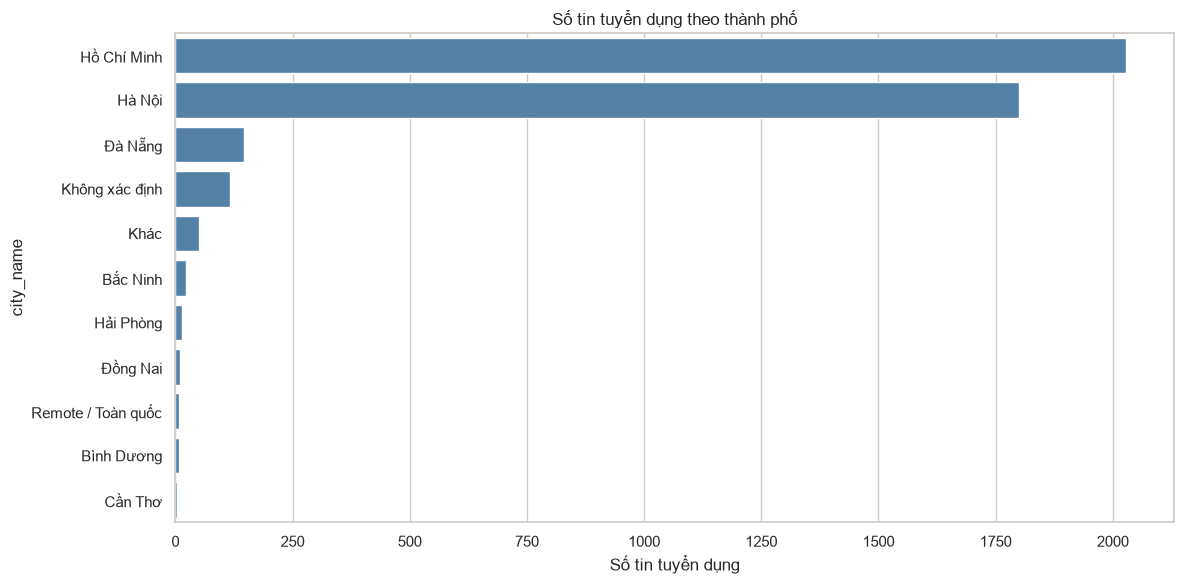


===== TIN TUYỂN DỤNG THEO VAI TRÒ =====


,role_name,so_tin
0,Backend Developer,1173
1,Fullstack Developer,479
2,Software Engineer (Chung),419
3,Other IT Roles,373
4,Frontend Developer,365
5,Mobile Developer,304
6,Data / AI / Machine Learning,303
7,QA / QC / Tester,288
8,DevOps / Cloud / System,231
9,BA / PM / Product,175


Đã xuất: jobs_by_role.png


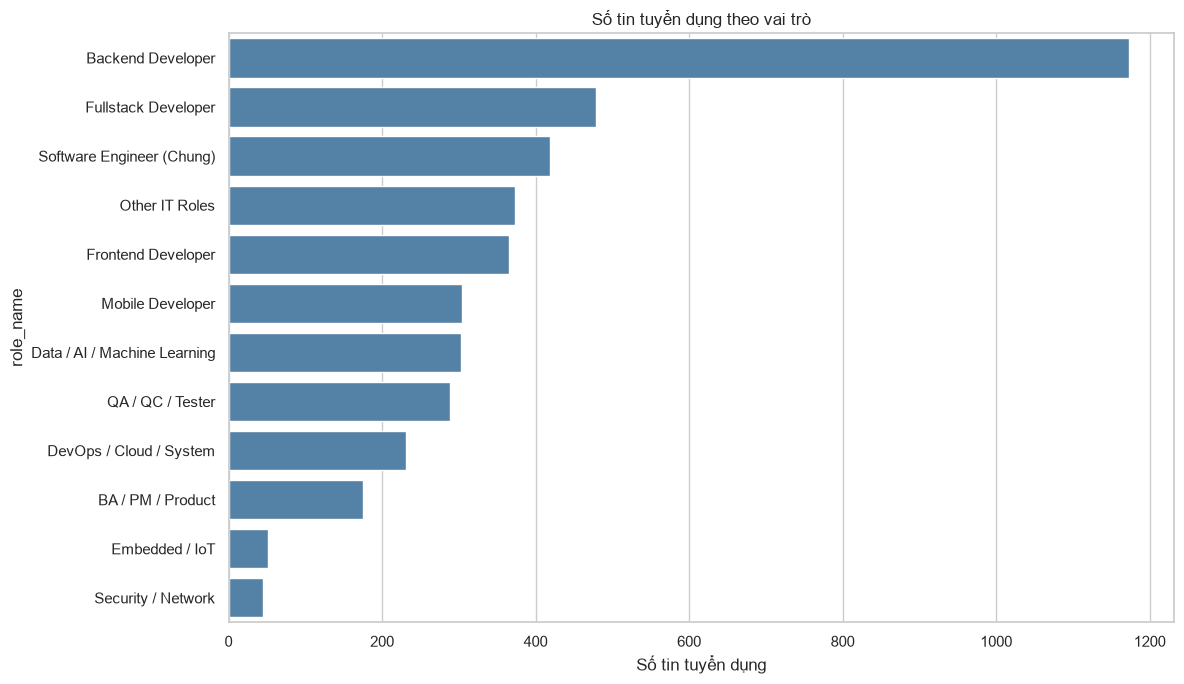

In [3]:

# ==================================================
# PHÂN TÍCH 1: TỔNG QUAN
# ==================================================

# Ghép dữ liệu thành phố và vai trò
tong_quan = jobs.merge(dim_city, on="city_id", how="left")
tong_quan = tong_quan.merge(dim_role, on="role_id", how="left")

# Đọc dữ liệu công ty
dim_company = pd.read_csv(DATA_DIR / "dim_company.csv")
tong_quan = tong_quan.merge(dim_company, on="company_id", how="left")

# --------------------------------------------------
# 1. CÁC CHỈ SỐ TỔNG QUAN
# --------------------------------------------------

tong_so_tin = tong_quan["job_id"].nunique()
tong_so_cong_ty = tong_quan["company_id"].nunique()
luong_trung_vi = tong_quan["salary_avg"].median()

print("===== CÁC CHỈ SỐ TỔNG QUAN =====")
print(f"Tổng số tin tuyển dụng: {tong_so_tin:,}")
print(f"Tổng số công ty tuyển dụng: {tong_so_cong_ty:,}")
print(f"Lương trung vị: {luong_trung_vi:.2f} triệu VNĐ/tháng")

# --------------------------------------------------
# 2. TIN TUYỂN DỤNG THEO THÀNH PHỐ
# --------------------------------------------------

tin_theo_thanh_pho = (
    tong_quan.groupby("city_name")["job_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="so_tin")
)

print("\n===== TIN TUYỂN DỤNG THEO THÀNH PHỐ =====")
display(tin_theo_thanh_pho)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=tin_theo_thanh_pho,
    x="so_tin",
    y="city_name",
    color="steelblue"
)

plt.title("Số tin tuyển dụng theo thành phố")
plt.xlabel("Số tin tuyển dụng")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. TIN TUYỂN DỤNG THEO VAI TRÒ 
# --------------------------------------------------

tin_theo_vai_tro = (
    tong_quan.groupby("role_name")["job_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="so_tin")
)

print("\n===== TIN TUYỂN DỤNG THEO VAI TRÒ =====")
display(tin_theo_vai_tro)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=tin_theo_vai_tro,
    x="so_tin",
    y="role_name",
    color="steelblue"
)

plt.title("Số tin tuyển dụng theo vai trò")
plt.xlabel("Số tin tuyển dụng")
plt.tight_layout()
plt.show()


===== TOP 15 KỸ NĂNG ĐƯỢC YÊU CẦU NHIỀU NHẤT =====


,skill_name,so_tin
0,JavaScript,1010
1,Java,989
2,Python,807
3,Git,644
4,AWS,622
5,SQL,599
6,React,540
7,Docker,533
8,Agile,503
9,CI/CD,488


Đã xuất: top_15_skills.png


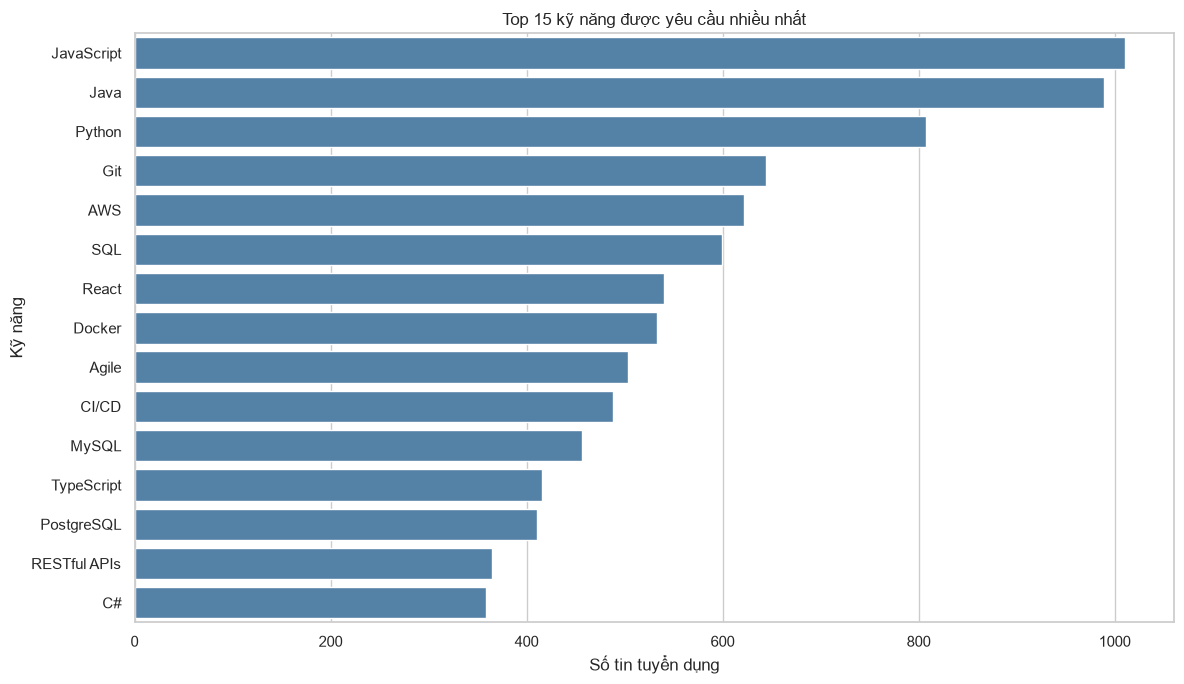


===== KỸ NĂNG THEO VAI TRÒ =====


skill_name,AWS,Agile,CI/CD,Docker,Git,Java,JavaScript,Python,React,SQL
role_name,,,,,,,,,,
BA / PM / Product,6.0,73.0,0.0,2.0,1.0,10.0,3.0,2.0,0.0,14.0
Backend Developer,260.0,103.0,193.0,272.0,229.0,536.0,215.0,317.0,68.0,283.0
Data / AI / Machine Learning,39.0,13.0,4.0,19.0,17.0,24.0,21.0,145.0,5.0,68.0
DevOps / Cloud / System,75.0,14.0,55.0,49.0,22.0,18.0,5.0,50.0,1.0,7.0
Embedded / IoT,0.0,2.0,4.0,0.0,6.0,6.0,0.0,9.0,0.0,0.0
Frontend Developer,39.0,40.0,42.0,23.0,116.0,22.0,273.0,12.0,196.0,10.0
Fullstack Developer,101.0,59.0,78.0,107.0,77.0,121.0,255.0,111.0,190.0,69.0
Mobile Developer,16.0,43.0,40.0,9.0,73.0,79.0,59.0,10.0,27.0,7.0
Other IT Roles,29.0,31.0,21.0,15.0,7.0,48.0,34.0,43.0,14.0,28.0


Đã xuất: skills_by_role_heatmap.png


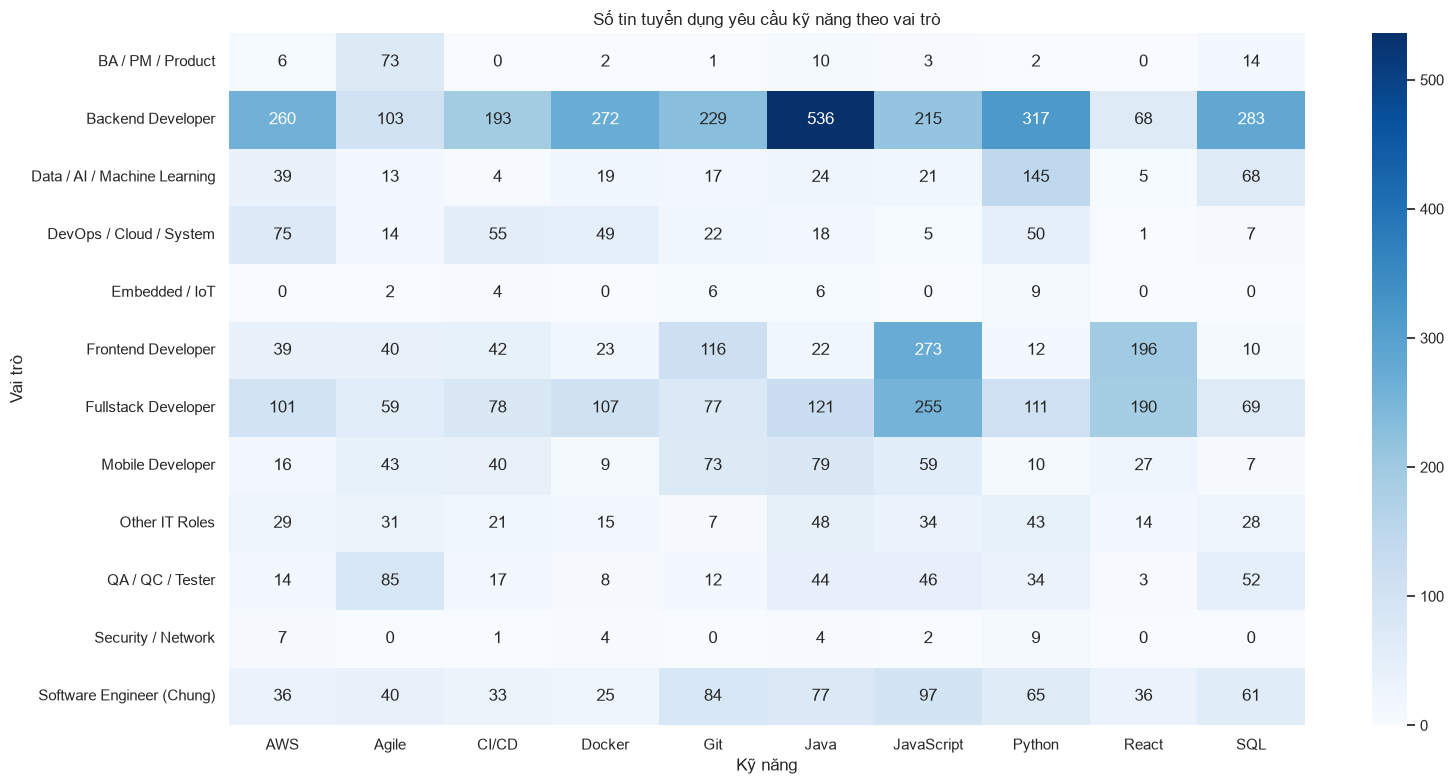


===== TỶ LỆ TIN TUYỂN DỤNG YÊU CẦU KỸ NĂNG =====


,skill_name,so_tin,ty_le
0,JavaScript,1010,24.007606
1,Java,989,23.508438
2,Python,807,19.182315
3,Git,644,15.307820
4,AWS,622,14.784882
5,SQL,599,14.238174
6,React,540,12.835750
7,Docker,533,12.669361
8,Agile,503,11.956263
9,CI/CD,488,11.599715


Đã xuất: skill_requirement_rate.png


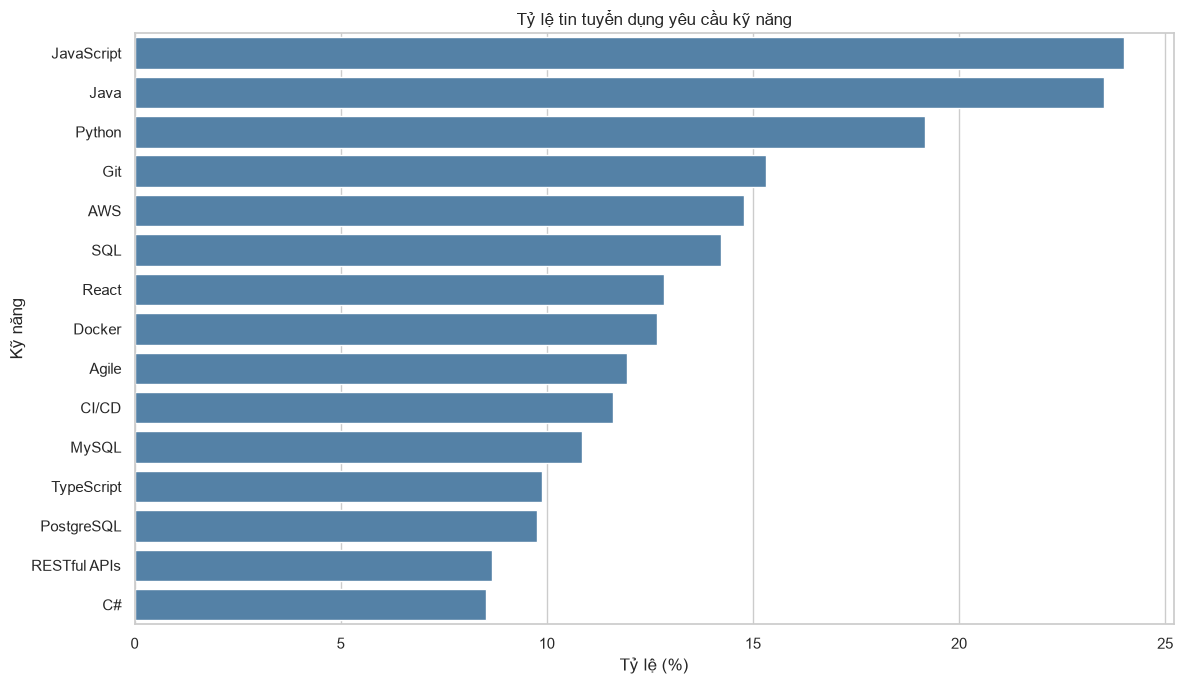

In [4]:

# ==================================================
# PHÂN TÍCH 2: KỸ NĂNG
# ==================================================

# Ghép dữ liệu kỹ năng và vai trò
ky_nang = fact_skills.merge(dim_skill, on="skill_id", how="left")
ky_nang = ky_nang.merge(dim_role, on="role_id", how="left")

# --------------------------------------------------
# 1. TOP 15 KỸ NĂNG ĐƯỢC YÊU CẦU NHIỀU NHẤT
# --------------------------------------------------

top_15_ky_nang = (
    ky_nang.groupby("skill_name")["job_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="so_tin")
)

print("===== TOP 15 KỸ NĂNG ĐƯỢC YÊU CẦU NHIỀU NHẤT =====")
display(top_15_ky_nang)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_15_ky_nang,
    x="so_tin",
    y="skill_name",
    color="steelblue"
)

plt.title("Top 15 kỹ năng được yêu cầu nhiều nhất")
plt.xlabel("Số tin tuyển dụng")
plt.ylabel("Kỹ năng")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. KỸ NĂNG THEO VAI TRÒ
# --------------------------------------------------

# Lấy 10 kỹ năng phổ biến nhất để so sánh giữa các vai trò
top_10_ky_nang = top_15_ky_nang.head(10)["skill_name"].tolist()

ky_nang_theo_vai_tro = (
    ky_nang[ky_nang["skill_name"].isin(top_10_ky_nang)]
    .groupby(["role_name", "skill_name"])["job_id"]
    .nunique()
    .reset_index(name="so_tin")
)

bang_ky_nang_theo_vai_tro = ky_nang_theo_vai_tro.pivot(
    index="role_name",
    columns="skill_name",
    values="so_tin"
).fillna(0)

print("\n===== KỸ NĂNG THEO VAI TRÒ =====")
display(bang_ky_nang_theo_vai_tro)

plt.figure(figsize=(16, 8))
sns.heatmap(
    bang_ky_nang_theo_vai_tro,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Số tin tuyển dụng yêu cầu kỹ năng theo vai trò")
plt.xlabel("Kỹ năng")
plt.ylabel("Vai trò")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. TỶ LỆ TIN TUYỂN DỤNG YÊU CẦU KỸ NĂNG
# --------------------------------------------------

tong_so_tin_tuyen_dung = jobs["job_id"].nunique()

ty_le_ky_nang = (
    ky_nang.groupby("skill_name")["job_id"]
    .nunique()
    .reset_index(name="so_tin")
)

ty_le_ky_nang["ty_le"] = (
    ty_le_ky_nang["so_tin"] / tong_so_tin_tuyen_dung * 100
)

ty_le_ky_nang = (
    ty_le_ky_nang
    .sort_values("ty_le", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\n===== TỶ LỆ TIN TUYỂN DỤNG YÊU CẦU KỸ NĂNG =====")
display(ty_le_ky_nang)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=ty_le_ky_nang,
    x="ty_le",
    y="skill_name",
    color="steelblue"
)

plt.title("Tỷ lệ tin tuyển dụng yêu cầu kỹ năng")
plt.xlabel("Tỷ lệ (%)")
plt.ylabel("Kỹ năng")
plt.tight_layout()
plt.show()


===== XU HƯỚNG SỐ TIN TUYỂN DỤNG THEO THỜI GIAN =====


,full_date,so_tin
0,2025-10-22,65
1,2025-10-23,83
2,2025-10-24,76
3,2025-10-25,87
4,2025-10-26,66
5,2025-10-27,68
6,2025-10-28,59
7,2025-10-29,93
8,2025-10-30,80
9,2025-10-31,75


Đã xuất: recruitment_trend.png


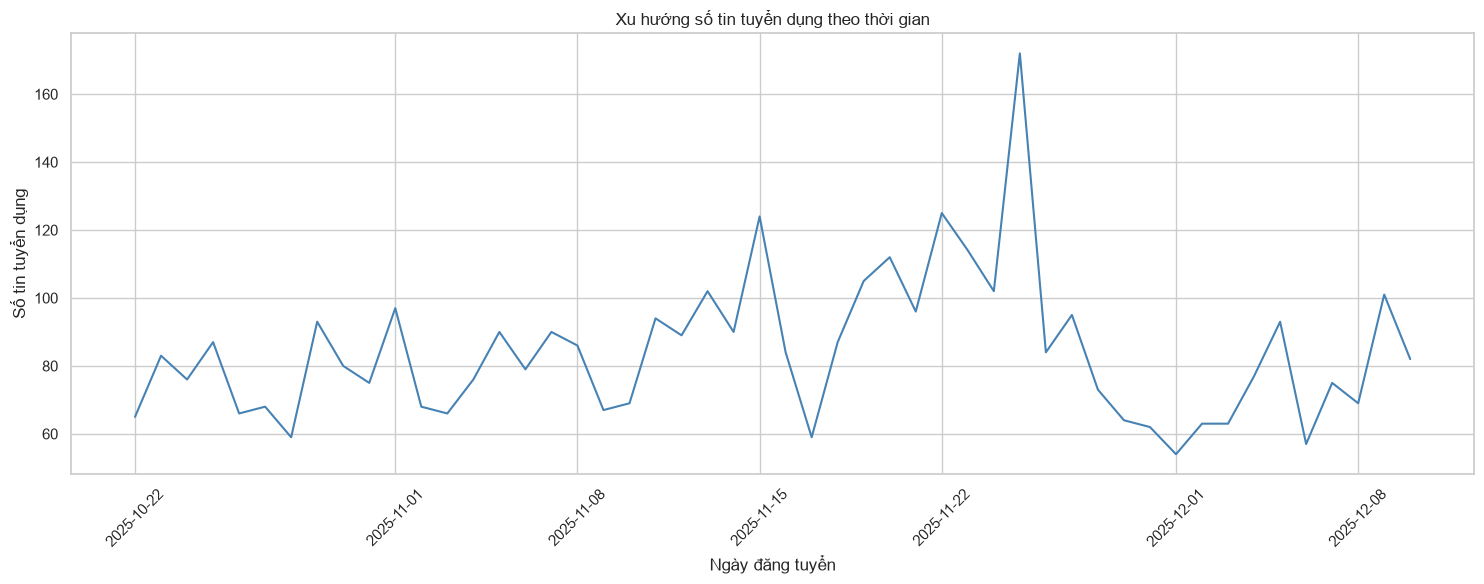

In [5]:

# ==================================================
# PHÂN TÍCH 3: XU HƯỚNG TUYỂN DỤNG THEO THỜI GIAN
# ==================================================

# Ghép dữ liệu ngày với tin tuyển dụng
xu_huong = jobs.merge(dim_date, on="date_id", how="left")

# --------------------------------------------------
# 1. XU HƯỚNG SỐ TIN TUYỂN DỤNG THEO THỜI GIAN
# --------------------------------------------------

xu_huong["full_date"] = pd.to_datetime(xu_huong["full_date"])

tin_theo_thoi_gian = (
    xu_huong.groupby("full_date")["job_id"]
    .nunique()
    .reset_index(name="so_tin")
    .sort_values("full_date")
)

print("===== XU HƯỚNG SỐ TIN TUYỂN DỤNG THEO THỜI GIAN =====")
display(tin_theo_thoi_gian)

plt.figure(figsize=(15, 6))
sns.lineplot(
    data=tin_theo_thoi_gian,
    x="full_date",
    y="so_tin",
    color="steelblue"
)

plt.title("Xu hướng số tin tuyển dụng theo thời gian")
plt.xlabel("Ngày đăng tuyển")
plt.ylabel("Số tin tuyển dụng")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


===== LƯƠNG TRUNG VỊ THEO VAI TRÒ =====


,role_name,luong_trung_vi,so_tin_cong_khai
0,Security / Network,50.80,3
1,BA / PM / Product,38.10,33
2,DevOps / Cloud / System,38.10,46
3,Backend Developer,38.10,164
4,Fullstack Developer,33.00,80
5,QA / QC / Tester,31.80,45
6,Data / AI / Machine Learning,30.00,47
7,Frontend Developer,29.20,43
8,Mobile Developer,29.20,49
9,Software Engineer (Chung),25.00,41


Đã xuất: salary_by_role.png


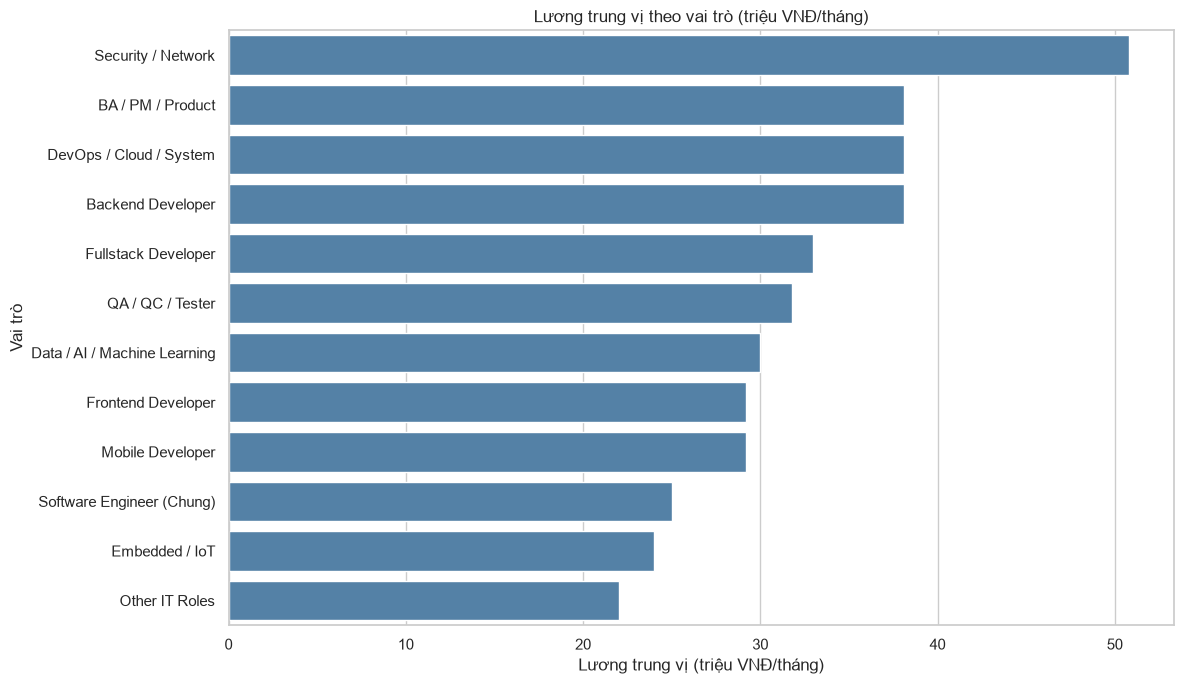


===== LƯƠNG TRUNG VỊ THEO CẤP BẬC =====


,level_name,luong_trung_vi,so_tin_cong_khai
0,Lead / Manager,40.60,201
1,Senior,40.00,97
2,Không xác định,35.60,31
3,Intern / Fresher,28.55,44
4,Middle,27.50,175
5,Junior,17.00,86


Đã xuất: salary_by_level.png


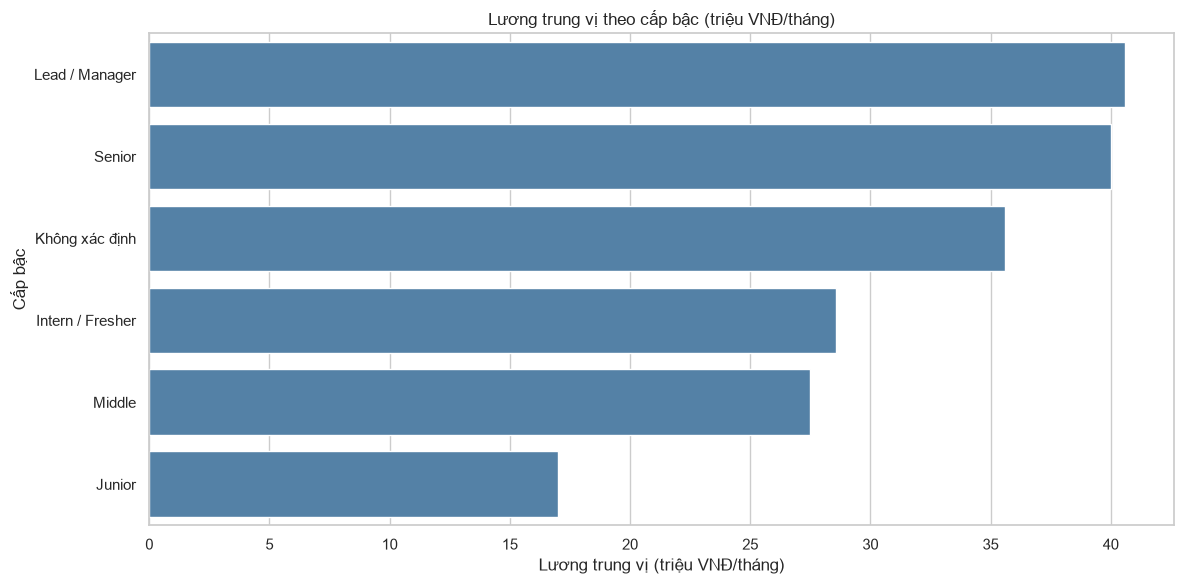


===== TỶ LỆ TIN TUYỂN DỤNG CÓ CÔNG KHAI LƯƠNG =====


,trang_thai,so_tin,ty_le
0,Có công khai lương,634,15.070121
1,Không công khai lương,3573,84.929879


Đã xuất: salary_disclosure_pie.png


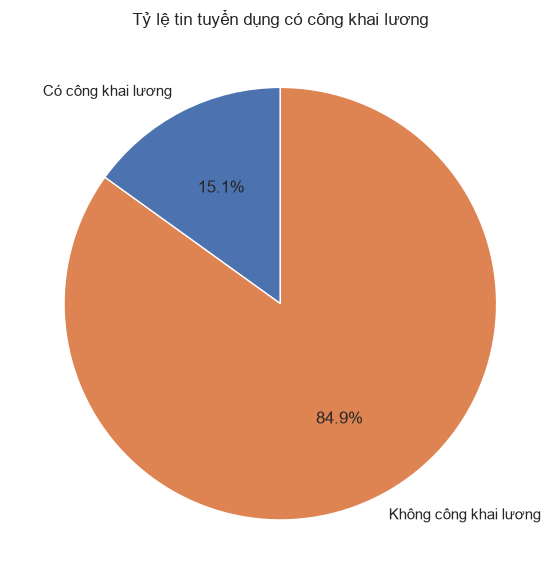


Số tin công khai lương: 634/4,207
Tỷ lệ công khai lương: 15.1%

===== GHI CHÚ PHÂN TÍCH LƯƠNG =====
Chỉ 15.1% tin tuyển dụng (634/4,207) có công khai lương.
LinkedIn không có dữ liệu lương.
Lương trung vị mang tính tham khảo do số lượng tin công khai lương hạn chế.
Security/Network chỉ có 3 tin và Intern/Fresher chỉ có 19 tin có lương.


In [6]:

# ==================================================
# PHÂN TÍCH 4: LƯƠNG
# ==================================================

# Ghép dữ liệu vai trò và cấp bậc
luong = jobs.merge(dim_role, on="role_id", how="left")
luong = luong.merge(dim_level, on="level_id", how="left")

# --------------------------------------------------
# 1. LƯƠNG TRUNG VỊ THEO VAI TRÒ
# --------------------------------------------------

luong_theo_vai_tro = (
    luong[luong["salary_avg"].notna()]
    .groupby("role_name")
    .agg(
        luong_trung_vi=("salary_avg", "median"),
        so_tin_cong_khai=("job_id", "nunique")
    )
    .sort_values("luong_trung_vi", ascending=False)
    .reset_index()
)

print("===== LƯƠNG TRUNG VỊ THEO VAI TRÒ =====")
display(luong_theo_vai_tro)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=luong_theo_vai_tro,
    x="luong_trung_vi",
    y="role_name",
    color="steelblue"
)

plt.title("Lương trung vị theo vai trò (triệu VNĐ/tháng)")
plt.xlabel("Lương trung vị (triệu VNĐ/tháng)")
plt.ylabel("Vai trò")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. LƯƠNG TRUNG VỊ THEO CẤP BẬC
# --------------------------------------------------

luong_theo_cap_bac = (
    luong[luong["salary_avg"].notna()]
    .groupby("level_name")
    .agg(
        luong_trung_vi=("salary_avg", "median"),
        so_tin_cong_khai=("job_id", "nunique")
    )
    .sort_values("luong_trung_vi", ascending=False)
    .reset_index()
)

print("\n===== LƯƠNG TRUNG VỊ THEO CẤP BẬC =====")
display(luong_theo_cap_bac)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=luong_theo_cap_bac,
    x="luong_trung_vi",
    y="level_name",
    color="steelblue"
)

plt.title("Lương trung vị theo cấp bậc (triệu VNĐ/tháng)")
plt.xlabel("Lương trung vị (triệu VNĐ/tháng)")
plt.ylabel("Cấp bậc")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. TỶ LỆ TIN TUYỂN DỤNG CÓ CÔNG KHAI LƯƠNG
# --------------------------------------------------

tong_so_tin = jobs["job_id"].nunique()

so_tin_cong_khai_luong = jobs[
    jobs["salary_avg"].notna()
]["job_id"].nunique()

so_tin_khong_cong_khai_luong = (
    tong_so_tin - so_tin_cong_khai_luong
)

ty_le_cong_khai_luong = (
    so_tin_cong_khai_luong / tong_so_tin * 100
)

ty_le_khong_cong_khai_luong = (
    so_tin_khong_cong_khai_luong / tong_so_tin * 100
)

bang_cong_khai_luong = pd.DataFrame({
    "trang_thai": [
        "Có công khai lương",
        "Không công khai lương"
    ],
    "so_tin": [
        so_tin_cong_khai_luong,
        so_tin_khong_cong_khai_luong
    ],
    "ty_le": [
        ty_le_cong_khai_luong,
        ty_le_khong_cong_khai_luong
    ]
})

print("\n===== TỶ LỆ TIN TUYỂN DỤNG CÓ CÔNG KHAI LƯƠNG =====")
display(bang_cong_khai_luong)

plt.figure(figsize=(8, 6))
plt.pie(
    bang_cong_khai_luong["so_tin"],
    labels=bang_cong_khai_luong["trang_thai"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Tỷ lệ tin tuyển dụng có công khai lương")
plt.tight_layout()
plt.show()

print(f"\nSố tin công khai lương: {so_tin_cong_khai_luong:,}/{tong_so_tin:,}")
print(f"Tỷ lệ công khai lương: {ty_le_cong_khai_luong:.1f}%")

# --------------------------------------------------
# 4. GHI CHÚ PHÂN TÍCH LƯƠNG
# --------------------------------------------------

print("\n===== GHI CHÚ PHÂN TÍCH LƯƠNG =====")
print(
    f"Chỉ {ty_le_cong_khai_luong:.1f}% tin tuyển dụng "
    f"({so_tin_cong_khai_luong:,}/{tong_so_tin:,}) có công khai lương."
)
print("LinkedIn không có dữ liệu lương.")
print("Lương trung vị mang tính tham khảo do số lượng tin công khai lương hạn chế.")
print("Security/Network chỉ có 3 tin và Intern/Fresher chỉ có 19 tin có lương.")


In [7]:
# Xuất toàn bộ bảng kết quả EDA

tables = {
    "jobs_by_city": tin_theo_thanh_pho,
    "jobs_by_role": tin_theo_vai_tro,
    "top_15_skills": top_15_ky_nang,
    "skills_by_role": bang_ky_nang_theo_vai_tro,
    "skill_requirement_rate": ty_le_ky_nang,
    "recruitment_trend": tin_theo_thoi_gian,
    "salary_by_role": luong_theo_vai_tro,
    "salary_by_level": luong_theo_cap_bac,
    "salary_disclosure": bang_cong_khai_luong
}

for name, df in tables.items():
    df.to_csv(
        TABLE_DIR / f"{name}.csv",
        index=True,
        encoding="utf-8-sig"
    )

    print(f"Đã xuất bảng: {name}.csv")

print("\nHOÀN TẤT XUẤT KẾT QUẢ EDA")
print("Charts:", CHART_DIR)
print("Tables:", TABLE_DIR)

Đã xuất bảng: jobs_by_city.csv
Đã xuất bảng: jobs_by_role.csv
Đã xuất bảng: top_15_skills.csv
Đã xuất bảng: skills_by_role.csv
Đã xuất bảng: skill_requirement_rate.csv
Đã xuất bảng: recruitment_trend.csv
Đã xuất bảng: salary_by_role.csv
Đã xuất bảng: salary_by_level.csv
Đã xuất bảng: salary_disclosure.csv

HOÀN TẤT XUẤT KẾT QUẢ EDA
Charts: ..\results\charts
Tables: ..\results\tables



# KẾT LUẬN PHÂN TÍCH KHÁM PHÁ DỮ LIỆU

Qua quá trình phân tích khám phá dữ liệu, dự án đã tổng hợp được đặc điểm thị trường tuyển dụng IT tại Việt Nam thông qua số lượng tin tuyển dụng, phân bố theo thành phố và vai trò, nhu cầu kỹ năng, xu hướng đăng tuyển và mức lương.

Các kết quả phân tích là cơ sở để xây dựng dashboard trực quan, hỗ trợ người dùng theo dõi và khám phá thông tin tuyển dụng IT.
